# Wettervergleich Berlin 2025

Dieses Notebook vergleicht tägliche Temperatur- und Niederschlagsdaten für Berlin im Kalenderjahr **2025**. Wir stellen die Open-Meteo-Archivdaten den gemessenen Tageswerten der DWD-Station Berlin-Tempelhof gegenüber und betrachten die Unterschiede in Tabellen, Kennzahlen und Diagrammen.

Für den Datenabruf ist eine Internetverbindung erforderlich. Die Diagramme verwenden Matplotlib. Führe die Zellen der Reihe nach mit **Shift+Enter** aus.

## 1. Quellen und Zeitraum

- **Open-Meteo:** tägliche Werte für ein Modellgitter am Berliner Stadtzentrum (52.52° N, 13.405° E).
- **DWD:** Stationsmessungen von Berlin-Tempelhof, Stations-ID **00433**.
- **Zeitraum:** 1. Januar bis 31. Dezember 2025.

Die Quellen sind nicht identisch: Eine Stationsmessung und ein Wert aus einem Wettermodell/Reanalyseprodukt können sich durch Standort und Mess- bzw. Berechnungsmethode unterscheiden. Der Vergleich zeigt diese Abweichungen, nicht automatisch einen Fehler einer Quelle.

In [8]:
from datetime import datetime
from urllib.parse import urlencode
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO, StringIO
import csv
import json

jahr = 2025

# Open-Meteo: tägliche Werte für das Berliner Stadtzentrum
open_meteo_parameter = {
    "latitude": 52.52,
    "longitude": 13.405,
    "start_date": f"{jahr}-01-01",
    "end_date": f"{jahr}-12-31",
    "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
    "timezone": "Europe/Berlin",
}
open_meteo_url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(open_meteo_parameter)
with urlopen(open_meteo_url, timeout=60) as antwort:
    open_meteo = json.load(antwort)

open_daily = open_meteo["daily"]
open_temperatur_max = dict(zip(open_daily["time"], open_daily["temperature_2m_max"]))
open_temperatur_min = dict(zip(open_daily["time"], open_daily["temperature_2m_min"]))
open_niederschlag = dict(zip(open_daily["time"], open_daily["precipitation_sum"]))

# DWD: historische Klimatageswerte der Station Berlin-Tempelhof (00433)
dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/historical/"
    "tageswerte_KL_00433_19480101_20251231_hist.zip"
)
with urlopen(dwd_url, timeout=60) as antwort:
    dwd_zip = ZipFile(BytesIO(antwort.read()))
dwd_text_name = next(name for name in dwd_zip.namelist() if name.startswith("produkt_klima_tag_") and name.endswith(".txt"))
dwd_text = dwd_zip.read(dwd_text_name).decode("latin1")

dwd_temperatur_max = {}
dwd_temperatur_min = {}
dwd_niederschlag = {}
leser = csv.DictReader(StringIO(dwd_text), delimiter=";")
for zeile in leser:
    daten = {schluessel.strip(): (wert or "").strip() for schluessel, wert in zeile.items()}
    datum = daten.get("MESS_DATUM", "")
    if not datum.startswith(str(jahr)):
        continue

    def dwd_wert(spaltenname):
        wert = daten.get(spaltenname, "")
        return None if wert in ("", "-999") else float(wert)

    maximum = dwd_wert("TXK")
    minimum = dwd_wert("TNK")
    regen = dwd_wert("RSK")
    iso_datum = f"{datum[:4]}-{datum[4:6]}-{datum[6:8]}"
    if maximum is not None:
        dwd_temperatur_max[iso_datum] = maximum
    if minimum is not None:
        dwd_temperatur_min[iso_datum] = minimum
    if regen is not None:
        dwd_niederschlag[iso_datum] = regen

temperatur_tage = sorted(
    datum for datum in set(open_temperatur_max) & set(dwd_temperatur_max)
    if open_temperatur_max[datum] is not None
)
niederschlag_tage = sorted(
    datum for datum in set(open_niederschlag) & set(dwd_niederschlag)
    if open_niederschlag[datum] is not None
)

print(f"Jahr: {jahr}")
print("Open-Meteo: Berliner Stadtzentrum (52.52 N, 13.405 E)")
print("DWD: Berlin-Tempelhof, Stations-ID 00433")
print(f"Abgleichbare Tage für Höchsttemperatur: {len(temperatur_tage)}")
print(f"Abgleichbare Tage für Niederschlag: {len(niederschlag_tage)}")

URLError: <urlopen error _ssl.c:1063: The handshake operation timed out>

## 2. Datenabdeckung prüfen

Zuerst prüfen wir, für wie viele Tage beide Quellen gültige Werte liefern. Die kleine Tabelle zeigt einen Ausschnitt der täglichen Höchsttemperaturen und macht die Differenz pro Tag sichtbar.

In [ ]:
print(f"Gemeinsame Tage Temperatur: {len(temperatur_tage)}")
print(f"Gemeinsame Tage Niederschlag: {len(niederschlag_tage)}")
print("\nAusschnitt: Tageshöchsttemperaturen")
print(f"{'Datum':<12} {'Open-Meteo':>12} {'DWD':>8} {'Differenz':>11}")
print("-" * 47)

for datum in temperatur_tage[:10]:
    open_wert = open_temperatur_max[datum]
    dwd_wert = dwd_temperatur_max[datum]
    print(f"{datum:<12} {open_wert:>10.1f} °C {dwd_wert:>6.1f} °C {open_wert - dwd_wert:>8.1f} °C")

Gemeinsame Tage Temperatur: 365
Gemeinsame Tage Niederschlag: 365

Ausschnitt: Tageshöchsttemperaturen
Datum          Open-Meteo      DWD   Differenz
-----------------------------------------------
2025-01-01          6.9 °C    8.5 °C     -1.6 °C
2025-01-02          6.7 °C    8.4 °C     -1.7 °C
2025-01-03          2.4 °C    3.8 °C     -1.4 °C
2025-01-04          0.8 °C    0.6 °C      0.2 °C
2025-01-05          1.4 °C    1.2 °C      0.2 °C
2025-01-06         11.6 °C   12.8 °C     -1.2 °C
2025-01-07          7.7 °C    9.4 °C     -1.7 °C
2025-01-08          4.2 °C    4.7 °C     -0.5 °C
2025-01-09          1.2 °C    1.5 °C     -0.3 °C
2025-01-10          1.1 °C    1.7 °C     -0.6 °C


## 3. Jahresvergleich berechnen

Für die Tageshöchsttemperatur berechnen wir mittleren absoluten Fehler und mittlere Abweichung. Die Abweichung ist definiert als **Open-Meteo minus DWD**: Ein positiver Wert bedeutet also, dass Open-Meteo im Mittel höhere Werte liefert. Beim Niederschlag vergleichen wir die Jahressummen und die mittlere tägliche Abweichung.

In [ ]:
open_max = [open_temperatur_max[tag] for tag in temperatur_tage]
dwd_max = [dwd_temperatur_max[tag] for tag in temperatur_tage]
temperatur_differenzen = [open_wert - dwd_wert for open_wert, dwd_wert in zip(open_max, dwd_max)]

open_regen = [open_niederschlag[tag] for tag in niederschlag_tage]
dwd_regen = [dwd_niederschlag[tag] for tag in niederschlag_tage]
regen_differenzen = [open_wert - dwd_wert for open_wert, dwd_wert in zip(open_regen, dwd_regen)]

print("Tageshöchsttemperatur")
print(f"  Mittel Open-Meteo: {sum(open_max) / len(open_max):.1f} °C")
print(f"  Mittel DWD:        {sum(dwd_max) / len(dwd_max):.1f} °C")
print(f"  Mittlerer absoluter Unterschied: {sum(abs(wert) for wert in temperatur_differenzen) / len(temperatur_differenzen):.2f} °C")
print(f"  Mittlere Abweichung (Open-Meteo - DWD): {sum(temperatur_differenzen) / len(temperatur_differenzen):+.2f} °C")

print("\nNiederschlag")
print(f"  Jahressumme Open-Meteo: {sum(open_regen):.1f} mm")
print(f"  Jahressumme DWD:        {sum(dwd_regen):.1f} mm")
print(f"  Mittlere tägliche Abweichung (Open-Meteo - DWD): {sum(regen_differenzen) / len(regen_differenzen):+.2f} mm")
print(f"  Regentage ab 1 mm laut DWD: {sum(wert >= 1 for wert in dwd_regen)}")

Tageshöchsttemperatur
  Mittel Open-Meteo: 14.7 °C
  Mittel DWD:        15.6 °C
  Mittlerer absoluter Unterschied: 1.14 °C
  Mittlere Abweichung (Open-Meteo - DWD): -0.95 °C

Niederschlag
  Jahressumme Open-Meteo: 610.5 mm
  Jahressumme DWD:        458.5 mm
  Mittlere tägliche Abweichung (Open-Meteo - DWD): +0.42 mm
  Regentage ab 1 mm laut DWD: 97


## 4. Diagramme

Die erste Grafik zeigt die tägliche Höchsttemperatur als Zeitreihe. Danach vergleichen wir die monatlichen Mittel der Tageshöchsttemperaturen und die monatlichen Niederschlagssummen.

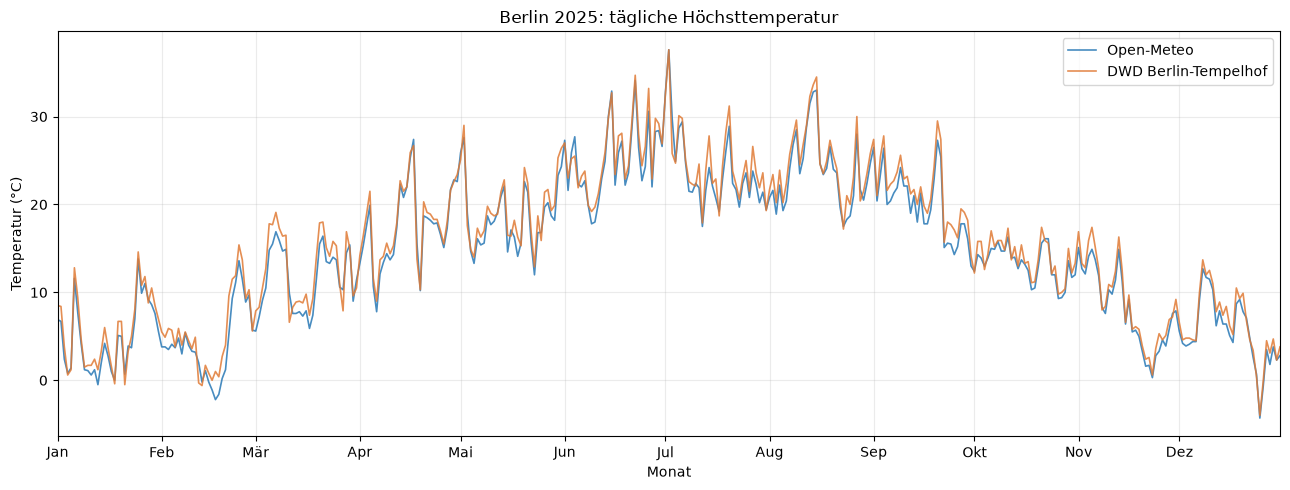

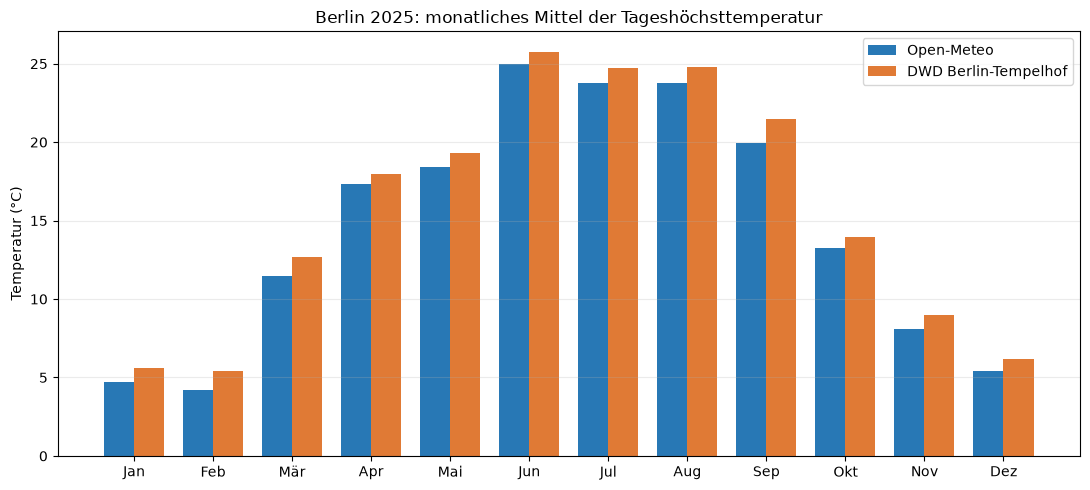

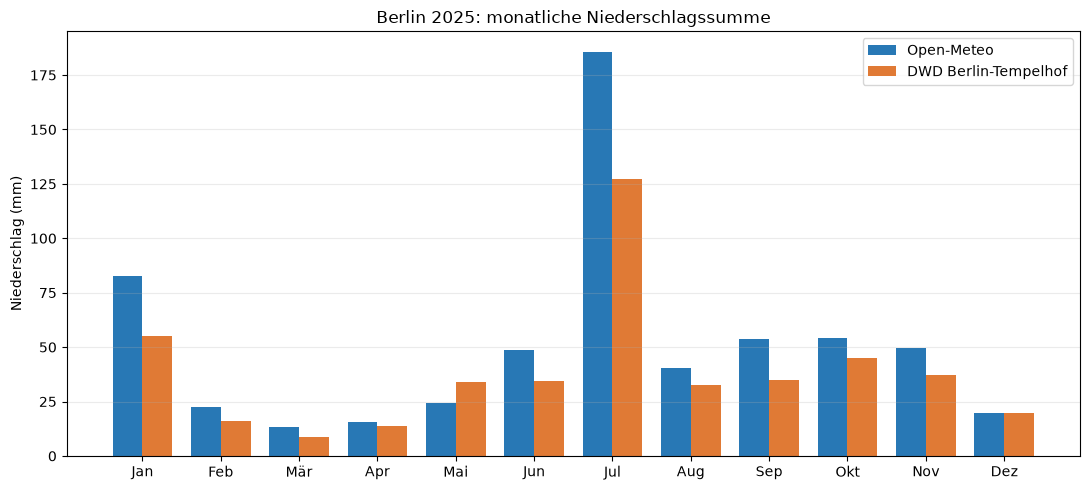

In [ ]:
import matplotlib.pyplot as plt

monate = list(range(1, 13))
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
monatstermine = [datetime(jahr, monat, 1) for monat in monate]

def monatswert(daten, werte, monat, mittelwert=False):
    auswahl = [werte[tag] for tag in daten if int(tag[5:7]) == monat]
    if not auswahl:
        return float("nan")
    return sum(auswahl) / len(auswahl) if mittelwert else sum(auswahl)

# 1. Tagesverlauf der Höchsttemperatur
plot_daten = [datetime.strptime(tag, "%Y-%m-%d") for tag in temperatur_tage]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(plot_daten, open_max, label="Open-Meteo", color="#2878B5", linewidth=1.2, alpha=0.85)
ax.plot(plot_daten, dwd_max, label="DWD Berlin-Tempelhof", color="#E07A35", linewidth=1.2, alpha=0.85)
ax.set_title("Berlin 2025: tägliche Höchsttemperatur")
ax.set_ylabel("Temperatur (°C)")
ax.set_xlabel("Monat")
ax.set_xticks(monatstermine, monatsnamen)
ax.set_xlim(datetime(jahr, 1, 1), datetime(jahr, 12, 31))
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

# 2. Monatliche Mittel der täglichen Höchsttemperatur
open_monatsmittel = [monatswert(temperatur_tage, open_temperatur_max, monat, mittelwert=True) for monat in monate]
dwd_monatsmittel = [monatswert(temperatur_tage, dwd_temperatur_max, monat, mittelwert=True) for monat in monate]
positionen = list(range(12))
breite = 0.38
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar([position - breite / 2 for position in positionen], open_monatsmittel, breite, label="Open-Meteo", color="#2878B5")
ax.bar([position + breite / 2 for position in positionen], dwd_monatsmittel, breite, label="DWD Berlin-Tempelhof", color="#E07A35")
ax.set_title("Berlin 2025: monatliches Mittel der Tageshöchsttemperatur")
ax.set_ylabel("Temperatur (°C)")
ax.set_xticks(positionen, monatsnamen)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

# 3. Monatliche Niederschlagssummen
open_monatsregen = [monatswert(niederschlag_tage, open_niederschlag, monat) for monat in monate]
dwd_monatsregen = [monatswert(niederschlag_tage, dwd_niederschlag, monat) for monat in monate]
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar([position - breite / 2 for position in positionen], open_monatsregen, breite, label="Open-Meteo", color="#2878B5")
ax.bar([position + breite / 2 for position in positionen], dwd_monatsregen, breite, label="DWD Berlin-Tempelhof", color="#E07A35")
ax.set_title("Berlin 2025: monatliche Niederschlagssumme")
ax.set_ylabel("Niederschlag (mm)")
ax.set_xticks(positionen, monatsnamen)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Hinweise zur Interpretation

- **Temperatur:** Verglichen werden die tägliche Höchsttemperatur aus Open-Meteo und das DWD-Tagesmaximum `TXK` in °C.
- **Niederschlag:** Verglichen werden die Tagesmengen und Jahressummen in Millimetern; im DWD-Datensatz heißt das Feld `RSK`.
- **Fehlwerte:** DWD-Werte mit dem Kennzeichen `-999` werden ausgelassen. In diesem Abruf stehen für beide Vergleiche 365 gemeinsame Tage zur Verfügung.
- **Standort und Methode:** Open-Meteo beschreibt ein Modell-/Reanalysegitter im Stadtzentrum. Der DWD misst an der Station Berlin-Tempelhof. Unterschiede sind daher erwartbar und kein direkter Qualitätsentscheid.

Datenquellen: [DWD Climate Data Center, Tageswerte Station 00433](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/) und [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api).